# Part 3D: The value of re-optimization


## Restating the question

At the end of 2015, use the **most recent 10 years** of data (2006/01 – 2015/12) to recompute a **long-only minimum-variance portfolio**, and over **2016/01 – 2023/07** compare its realized volatility with that of the portfolio that keeps the old weights from the end of 2004. Comment on the difference and on why this result may or may not be as expected.

| | Old portfolio | New portfolio |
|---|---|---|
| Date the weights are set | 2004/12/31 | 2015/12/31 |
| Data used to estimate $\Sigma$ | 1995/01 – 2004/12 | 2006/01 – 2015/12 |
| Origin | The 3A long-only weights, used directly | Re-optimized with the same method |
| Comparison period | 2016/01 – 2023/07 (out-of-sample for both) | Same as left |

**Intuition**: covariances change over time (3C already showed correlations rising from 0.40 to 0.59). The 2004 weights reflect the risk structure of the dot-com bubble era and are more than 11 years out of date by 2016. Re-optimizing is like "updating the map". The question is: is the updated map really more accurate?

## Additional analysis in this notebook

- **Old vs new weights and turnover**: how much of the position has to be replaced when moving from the old portfolio to the new one, used to explain where the difference in volatility comes from;
- **Sub-period check**: comparing before COVID (2016–2019) and after the start of COVID (2020–2023/07) separately.

## Outputs of this notebook

| File | Content |
|---|---|
| `output/tables/tab_3D_weights.csv` | Old and new weights and the change |
| `output/tables/tab_3D_reopt_vol.csv` | 2016–2023 volatility comparison (including sub-periods) |
| `output/figures/fig_3D_reopt_vol.png` | Main chart for the report: volatility of the old vs new portfolio |
| `output/figures/fig_3D_weights.png` | Old vs new weights chart |


## 1. Setup

The long-only minimum-variance solver is `min_var_long_only()` in `part3_common.py`, using exactly the same method as 3A (cvxpy + CLARABEL, weights below $10^{-6}$ set to zero, with an automatic check of the KKT optimality conditions).

In [19]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.ticker import MultipleLocator

HERE = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "part3_common.py").exists()
            or (p / "part3" / "python_source" / "part3_common.py").exists())
if not (HERE / "part3_common.py").exists():
    HERE = HERE / "part3" / "python_source"
sys.path.insert(0, str(HERE))
import part3_common as p3
from part3_common import config, utils, CN, EN

config.apply_style()
for k in ["3_seed", "3D_seed", "3D_oos"]:
    print(f"{k:8s}: {config.PERIODS[k]}")

3_seed  : ('1995-01', '2004-12')
3D_seed : ('2006-01', '2015-12')
3D_oos  : ('2016-01', '2023-07')


## 2. Load the data and the old weights

The old portfolio uses the long-only weights saved in 3A directly. To confirm that `min_var_long_only()` uses exactly the same method as 3A, we first recompute the portfolio with it on the 1995–2004 data; the result should be identical to 3A.

In [20]:
rets = p3.load_industry_returns()
W3A = p3.load_weights_3A()
seed_old = utils.select_period(rets, "3_seed")
seed_new = utils.select_period(rets, "3D_seed")
test = utils.select_period(rets, "3D_oos")

print(f"Old portfolio estimation period: {seed_old.index[0]} ~ {seed_old.index[-1]}, {len(seed_old)} months")
print(f"New portfolio estimation period: {seed_new.index[0]} ~ {seed_new.index[-1]}, {len(seed_new)} months")
print(f"Comparison period              : {test.index[0]} ~ {test.index[-1]}, {len(test)} months")
assert len(seed_new) == 120 and len(test) == 91 and seed_new.index.max() < test.index.min()

w_old = W3A["mv_long_only"].rename("old")
diff = (p3.min_var_long_only(seed_old) - w_old).abs().max()
print(f"\n2004 portfolio recomputed with the shared function, max difference from the 3A weights: {diff:.1e}  → same method ✓")

Old portfolio estimation period: 1995-01 ~ 2004-12, 120 months
New portfolio estimation period: 2006-01 ~ 2015-12, 120 months
Comparison period              : 2016-01 ~ 2023-07, 91 months

2004 portfolio recomputed with the shared function, max difference from the 3A weights: 0.0e+00  → same method ✓


## 3. Re-optimization: the new portfolio (as of 2015/12/31)

The problem is exactly the same as in 3A, except that $\Sigma$ is now estimated over 2006/01 – 2015/12:

$$
\min_{w}\; w^\top \Sigma_{2006\text{–}2015}\, w \qquad \text{s.t.}\quad \textstyle\sum_i w_i = 1,\quad w_i \ge 0
$$

In [21]:
w_new = p3.min_var_long_only(seed_new).rename("new")
print(f"Sum of weights: {w_new.sum():.6f}; industries held: {(w_new > 0).sum()} (old portfolio: {(w_old > 0).sum()})")
print("KKT optimality conditions checked inside the function ✓\n")
print("New portfolio holdings:")
for c, v in w_new[w_new > 0].sort_values(ascending=False).items():
    print(f"  {c:6s} {EN[c]:16s} {v:6.1%}")

Sum of weights: 1.000000; industries held: 5 (old portfolio: 12)
KKT optimality conditions checked inside the function ✓

New portfolio holdings:
  Food   Food products     37.4%
  Util   Utilities         23.3%
  Beer   Beer & liquor     21.2%
  Rtail  Retail            13.4%
  Gold   Precious metals    4.8%


## 4. Old vs new weights and turnover

**Turnover** = $\tfrac12\sum_i |w_i^{\text{new}} - w_i^{\text{old}}|$, i.e. the share of the position that has to be sold (and bought) to move from the old portfolio to the new one. 0% means no change at all; 100% means switching entirely to a different set of industries.

The table below lists only the industries held by at least one of the two portfolios.

In [22]:
cmpw = pd.DataFrame({"old": w_old, "new": w_new})
cmpw["change"] = cmpw["new"] - cmpw["old"]
held = cmpw[(cmpw[["old", "new"]] > 0).any(axis=1)].copy()
held = held.sort_values(["new", "old"], ascending=False)
held.insert(0, "Industry", [EN[c] for c in held.index])

turnover = 0.5 * (w_new - w_old).abs().sum()
common = held.index[(held["old"] > 0) & (held["new"] > 0)]
print(f"Turnover: {turnover:.1%}")
print(f"Industries held in both: {len(common)} ({', '.join(EN[c] for c in common)})")
print(f"Only in the old portfolio: {((held['old'] > 0) & (held['new'] == 0)).sum()}; only in the new portfolio: {((held['old'] == 0) & (held['new'] > 0)).sum()}")

out = held.drop(columns="Industry").rename(columns={"old": "Old weights (as of Dec 2004)",
                                                   "new": "New weights (as of Dec 2015)",
                                                   "change": "Change"})
out.insert(0, "Industry", [EN[c] for c in out.index])
out.index.name = "Code"
print("\nCSV →", utils.save_table(out, "tab_3D_weights", float_format="%.6f").relative_to(p3.ROOT))
held.style.format({"old": "{:.1%}", "new": "{:.1%}", "change": "{:+.1%}"})

Turnover: 73.5%
Industries held in both: 3 (Food products, Utilities, Precious metals)
Only in the old portfolio: 9; only in the new portfolio: 2

CSV → output\tables\tab_3D_weights.csv


,Industry,old,new,change
Food,Food products,9.1%,37.4%,+28.3%
Util,Utilities,16.7%,23.3%,+6.6%
Beer,Beer & liquor,0.0%,21.2%,+21.2%
Rtail,Retail,0.0%,13.4%,+13.4%
Gold,Precious metals,0.7%,4.8%,+4.0%
RlEst,Real estate,13.7%,0.0%,-13.7%
Hshld,Consumer goods,12.3%,0.0%,-12.3%
Agric,Agriculture,10.7%,0.0%,-10.7%
Drugs,Pharmaceuticals,9.5%,0.0%,-9.5%
Guns,Defense,9.3%,0.0%,-9.3%


### 4.1 How "stale" the old weights already were in the new estimation period

Looking back from the end of 2015: if the old portfolio had been held throughout 2006–2015, what would its volatility have been over those 10 years? Comparing it with the new portfolio over the same period (the new portfolio's in-sample period) shows how far the old weights had drifted from the latest risk structure.

In [23]:
pf = lambda w, df: df[w.index] @ w
v_old_0615 = utils.annualized_volatility(pf(w_old, seed_new))
v_new_0615 = utils.annualized_volatility(pf(w_new, seed_new))
print(f"2006–2015: old portfolio {v_old_0615:.1%}, new portfolio (in-sample) {v_new_0615:.1%}")

2006–2015: old portfolio 14.7%, new portfolio (in-sample) 10.3%


## 5. Volatility comparison, 2016/01 – 2023/07

Both portfolios are **out-of-sample** over this period; the method is the same as in 3C (fixed weights, rebalanced monthly to target, annualized volatility = standard deviation of monthly returns × √12). As before, the reference is the equally weighted portfolio of the 49 industries; to leave it out, change `SHOW_REFERENCE` to `False`.

In [24]:
SHOW_REFERENCE = True

r_old, r_new, r_ew = pf(w_old, test), pf(w_new, test), test.mean(axis=1)
v_old, v_new, v_ew = (utils.annualized_volatility(x) for x in (r_old, r_new, r_ew))
print(f"Old portfolio (2004 weights): {v_old:.2%}")
print(f"New portfolio (2015 weights): {v_new:.2%}")
print(f"Difference (new − old)      : {v_new - v_old:+.2%}, relative reduction {1 - v_new / v_old:.0%}")
print(f"Reference: equal weight, 49 industries: {v_ew:.2%}")
print(f"\nNew portfolio out-of-sample / in-sample = {v_new:.1%} / {v_new_0615:.1%} = ×{v_new / v_new_0615:.2f}")

Old portfolio (2004 weights): 14.52%
New portfolio (2015 weights): 12.81%
Difference (new − old)      : -1.71%, relative reduction 12%
Reference: equal weight, 49 industries: 17.82%

New portfolio out-of-sample / in-sample = 12.8% / 10.3% = ×1.24


## 6. Sub-period check

The comparison period includes the COVID pandemic. Split it into **before COVID (2016–2019)** and **after the start of COVID (2020–2023/07)** to see whether the new portfolio's advantage persists throughout, or comes mainly from the COVID shock.

The most severe phase, 2020/02–03, is only two months long, so a standard deviation is meaningless there; for that window we compare **cumulative returns** instead (this is also the crisis window used in 3E).

In [25]:
SUB = {"Full: Jan 2016 - Jul 2023": ("2016-01", "2023-07"),
       "Pre-COVID: 2016 - 2019": ("2016-01", "2019-12"),
       "COVID and after: 2020 - Jul 2023": ("2020-01", "2023-07")}
rows = {}
for name, (a, b) in SUB.items():
    rows[name] = {k: utils.annualized_volatility(r.loc[a:b]) for k, r in
                  [("Old (Dec 2004 weights)", r_old), ("New (Dec 2015 weights)", r_new), ("Equal weight (49 industries)", r_ew)]}
vol_tab = pd.DataFrame(rows).T
vol_tab["New − Old"] = vol_tab["New (Dec 2015 weights)"] - vol_tab["Old (Dec 2004 weights)"]
vol_tab.index.name = "Period (annualized volatility)"
print("CSV →", utils.save_table(vol_tab, "tab_3D_reopt_vol", float_format="%.6f").relative_to(p3.ROOT))

covid = {k: (1 + r.loc["2020-02":"2020-03"]).prod() - 1 for k, r in
         [("Old portfolio", r_old), ("New portfolio", r_new), ("Equal weight", r_ew)]}
print("\nCumulative return during the COVID shock, 2020/02–03: " + ", ".join(f"{k} {v:.1%}" for k, v in covid.items()))
vol_tab.style.format("{:.2%}").format("{:+.2%}", subset=["New − Old"])

CSV → output\tables\tab_3D_reopt_vol.csv

Cumulative return during the COVID shock, 2020/02–03: Old portfolio -21.2%, New portfolio -15.1%, Equal weight -24.6%


,Old (Dec 2004 weights),New (Dec 2015 weights),Equal weight (49 industries),New − Old
Period (annualized volatility),,,,
Full: Jan 2016 - Jul 2023,14.52%,12.81%,17.82%,-1.71%
Pre-COVID: 2016 - 2019,10.79%,10.31%,12.87%,-0.47%
COVID and after: 2020 - Jul 2023,17.93%,15.25%,22.25%,-2.68%


## 7. Charts for the report

### 7.1 Main chart: volatility of the old and new portfolios over 2016–2023

The three groups of bars correspond to the full period, before COVID and after the start of COVID. Colours: **old portfolio = light orange** (same colour family as the long-only portfolio in 3A–3C), **new portfolio = dark orange**, equal-weight reference = grey.

PNG → output\figures\fig_3D_reopt_vol.png


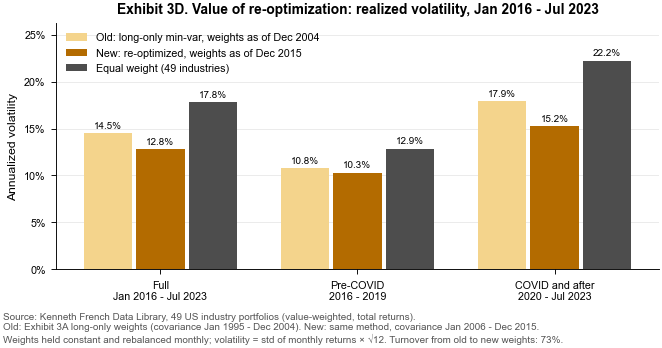

In [26]:
OLD_C = mcolors.to_hex(0.45 * np.array(mcolors.to_rgb(p3.PF_COLORS["mv_long_only"])) + 0.55)
NEW_C = "#B36B00"
series = [("Old: long-only min-var, weights as of Dec 2004", "Old (Dec 2004 weights)", OLD_C),
          ("New: re-optimized, weights as of Dec 2015", "New (Dec 2015 weights)", NEW_C)]
if SHOW_REFERENCE:
    series.append(("Equal weight (49 industries)", "Equal weight (49 industries)", config.COLOR_MARKET))

fig, ax = utils.new_fig("full")
x = np.arange(len(vol_tab))
bw = 0.8 / len(series)
for i, (label, col, colr) in enumerate(series):
    pos = x - 0.4 + bw * (i + 0.5)
    ax.bar(pos, vol_tab[col], width=bw * 0.92, color=colr, label=label)
    for p, v in zip(pos, vol_tab[col]):
        ax.text(p, v + 0.003, f"{v:.1%}", ha="center", va="bottom", fontsize=config.FONT_SMALL - 0.5)
ax.set_xticks(x, [s.replace(": ", "\n") for s in vol_tab.index])
utils.percent_axis(ax, "y")
ax.yaxis.set_major_locator(MultipleLocator(0.05))
ax.set_ylim(0, vol_tab[[c for _, c, _ in series]].to_numpy().max() * 1.18)
ax.set_ylabel("Annualized volatility")
ax.grid(axis="x", visible=False)
ax.set_axisbelow(True)
ax.legend(loc="upper left")
ax.set_title("Exhibit 3D. Value of re-optimization: realized volatility, Jan 2016 - Jul 2023")
src = (p3.SOURCE_FF49 + "\nOld: Exhibit 3A long-only weights (covariance Jan 1995 - Dec 2004). New: same method, covariance "
       "Jan 2006 - Dec 2015.\nWeights held constant and rebalanced monthly; volatility = std of monthly returns × √12. "
       f"Turnover from old to new weights: {turnover:.0%}.")
print("PNG →", utils.save_fig(fig, "fig_3D_reopt_vol", source=src).relative_to(p3.ROOT))
plt.show()

### 7.2 Old vs new weights chart

Only the industries held by at least one of the two portfolios are shown. The chart makes it plain that re-optimization is not a "fine-tuning" but a switch to a largely different set of industries.

PNG → output\figures\fig_3D_weights.png


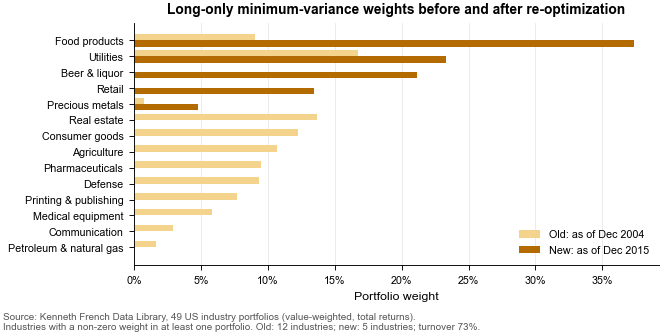

In [27]:
plot_df = held.iloc[::-1]
fig, ax = utils.new_fig("full")
y = np.arange(len(plot_df))
h = 0.4
ax.barh(y + h / 2, plot_df["old"], height=h, color=OLD_C, label="Old: as of Dec 2004")
ax.barh(y - h / 2, plot_df["new"], height=h, color=NEW_C, label="New: as of Dec 2015")
ax.set_yticks(y, [EN[c] for c in plot_df.index])
utils.percent_axis(ax, "x")
ax.xaxis.set_major_locator(MultipleLocator(0.05))
ax.set_xlabel("Portfolio weight")
ax.grid(axis="y", visible=False)
ax.set_axisbelow(True)
ax.legend(loc="lower right")
ax.set_title("Long-only minimum-variance weights before and after re-optimization")
src = (p3.SOURCE_FF49 + "\nIndustries with a non-zero weight in at least one portfolio. "
       f"Old: {(w_old > 0).sum()} industries; new: {(w_new > 0).sum()} industries; turnover {turnover:.0%}.")
print("PNG →", utils.save_fig(fig, "fig_3D_weights", source=src).relative_to(p3.ROOT))
plt.show()